In [4]:
import os
import pandas as pd
import numpy as np

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

# Regresión Lineal Multivariable0

## 1. Extracción y Carga de Datos
En este paso cargamos el conjunto de datos desde el archivo `.csv`, inspeccionamos la estructura de los datos y realizamos la separación entre la matriz de características independientes ($X$) y la variable objetivo ($y$).

In [ ]:
ruta_csv = os.path.join('datasets', 'diabetes.csv')
data_df = pd.read_csv(ruta_csv)

X = data_df.iloc[:, :20].values
y = data_df['Income'].values


m = y.size
print(f"Número de ejemplos de entrenamiento (m): {m}")

print('{:>12s}{:>12s}{:>12s}{:>12s}'.format('X[:,0]', 'X[:,1]', 'X[:,2]', 'y (Income)'))
print('-' * 48)
for i in range(10):
    print('{:12.2f}{:12.2f}{:12.2f}{:12.2f}'.format(X[i, 0], X[i, 1], X[i, 2], y[i]))

Número de ejemplos de entrenamiento (m): 253680
      X[:,0]      X[:,1]      X[:,2]  y (Income)
------------------------------------------------
        0.00        1.00        1.00        3.00
        0.00        0.00        0.00        1.00
        0.00        1.00        1.00        8.00
        0.00        1.00        0.00        6.00
        0.00        1.00        1.00        4.00
        0.00        1.00        1.00        8.00
        0.00        1.00        0.00        7.00
        0.00        1.00        1.00        4.00
        2.00        1.00        1.00        1.00
        0.00        0.00        0.00        3.00


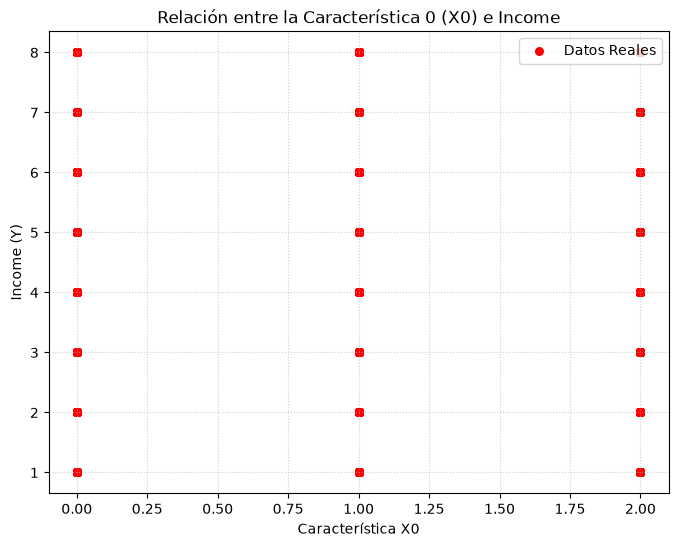

In [6]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(X[:, 0], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 0 (X0) e Income', fontsize=12)
pyplot.xlabel('Característica X0', fontsize=10)
pyplot.ylabel('Income (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

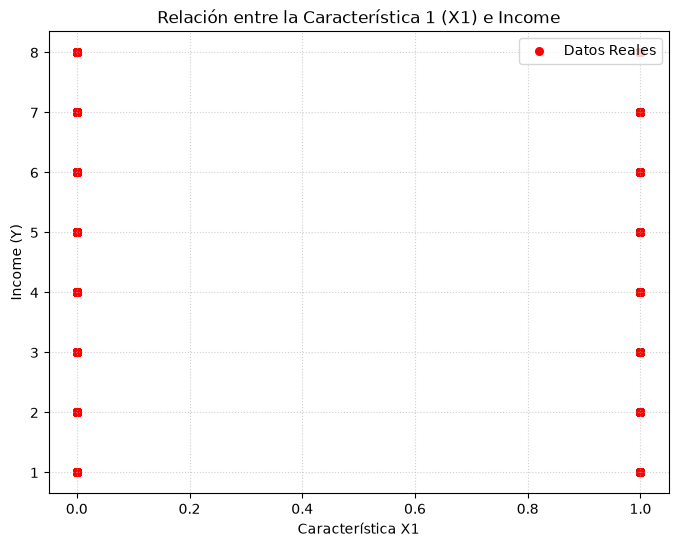

In [7]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(X[:, 1], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 1 (X1) e Income', fontsize=12)
pyplot.xlabel('Característica X1', fontsize=10)
pyplot.ylabel('Income (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

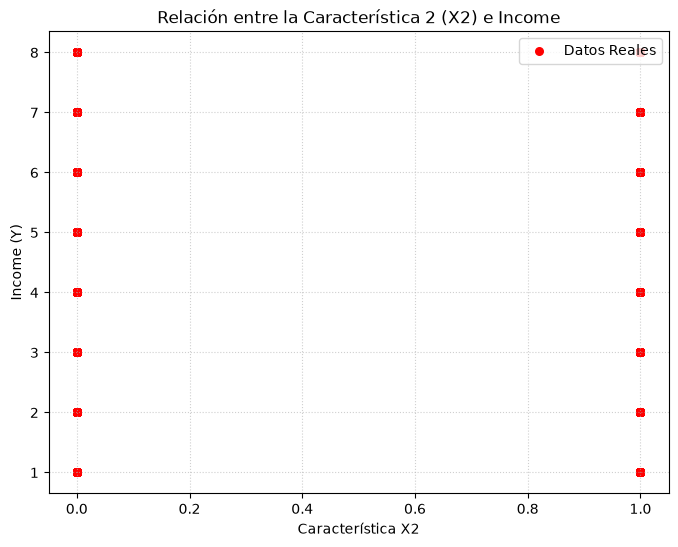

In [8]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(X[:, 2], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 2 (X2) e Income', fontsize=12)
pyplot.xlabel('Característica X2', fontsize=10)
pyplot.ylabel('Income (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

## 2. Normalización de Características (Feature Scaling)
Dado que las variables independientes suelen manejar distintas escalas de magnitud, aplicamos estandarización (Z-score) sobre la matriz $X$ para acelerar la convergencia del algoritmo de optimización:

$$x_j^{(i)} = \frac{x_j^{(i)} - \mu_j}{\sigma_j}$$

Donde:
* $\mu_j$ es la media de la característica $j$.
* $\sigma_j$ es la desviación estándar de la característica $j$.

In [9]:
def featureNormalize(X):
    
    X_norm = X.copy()
    
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma


X_norm, mu, sigma = featureNormalize(X)

print("Primeras 3 caracteristicas de las primeras 5 filas (Original):")
print(X[:5, :3])

print("\nPrimeras 3 características de las primeras 5 filas (Normalizado):")
print(X_norm[:5, :3])

Primeras 3 caracteristicas de las primeras 5 filas (Original):
[[0. 1. 1.]
 [0. 0. 0.]
 [0. 1. 1.]
 [0. 1. 0.]
 [0. 1. 1.]]

Primeras 3 características de las primeras 5 filas (Normalizado):
[[-0.42529222  1.15368814  1.16525449]
 [-0.42529222 -0.86678537 -0.85818163]
 [-0.42529222  1.15368814  1.16525449]
 [-0.42529222  1.15368814 -0.85818163]
 [-0.42529222  1.15368814  1.16525449]]


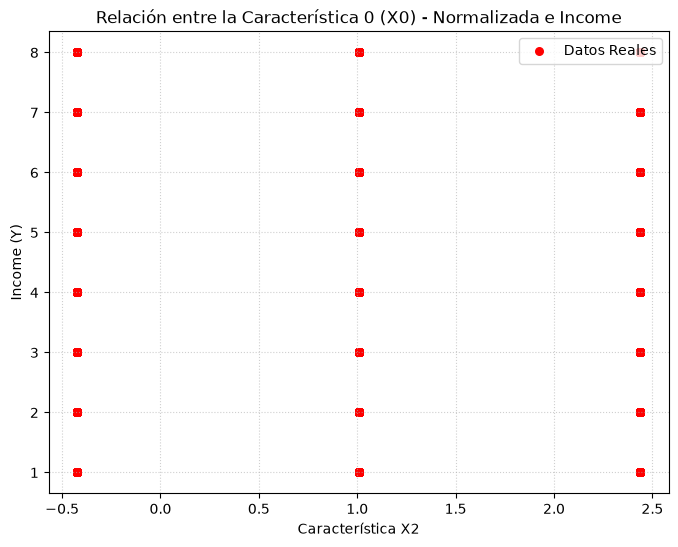

In [10]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(X_norm[:, 0], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 0 (X0) - Normalizada e Income', fontsize=12)
pyplot.xlabel('Característica X2', fontsize=10)
pyplot.ylabel('Income (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

## 3. Adición del Término de Sesgo ($X_0 = 1$)
Concatenamos un vector de unos en la primera columna de la matriz $X$ normalizada para dar soporte al parámetro de intersección $\theta_0$. La función de hipótesis toma la forma vectorial:

$$h_\theta(x) = \theta^T X = \theta_0 x_0 + \theta_1 x_1 + \dots + \theta_n x_n \quad \text{donde } x_0 = 1$$

In [11]:
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

print(f"Dimensiones de X antes: {X_norm.shape}")
print(f"Dimensiones de X ahora (con x0): {X.shape}")

print("\nPrimeras 3 filas y primeras 4 columnas de X:")
print(X[:3, :4])

Dimensiones de X antes: (253680, 20)
Dimensiones de X ahora (con x0): (253680, 21)

Primeras 3 filas y primeras 4 columnas de X:
[[ 1.         -0.42529222  1.15368814  1.16525449]
 [ 1.         -0.42529222 -0.86678537 -0.85818163]
 [ 1.         -0.42529222  1.15368814  1.16525449]]


## 4. Función de Costo $J(\theta)$ y Costo Inicial
Para medir la precisión de las predicciones definimos la función de costo basada en el Error Cuadrático Medio (MSE):

$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2$$

Evaluamos $J(\theta)$ inicializando el vector $\theta$ en ceros para calcular el **Costo Inicial** antes del entrenamiento.

In [12]:
def computeCostMulti(X, y, theta):
    
    m = y.shape[0]
    
    J = 0
    
    J = (1 / (2 * m)) * np.sum(np.square(np.dot(X, theta) - y))
    
    return J

theta_inicial = np.zeros(X.shape[1])

costo_inicial = computeCostMulti(X, y, theta_inicial)

print(f"Número de muestras (m): {y.shape[0]}")
print(f"Dimensiones de theta: {theta_inicial.shape}")
print(f"Costo inicial (con theta = 0): {costo_inicial:.4f}")

Número de muestras (m): 253680
Dimensiones de theta: (21,)
Costo inicial (con theta = 0): 20.4695


## 5. Optimización con Gradiente Descendente
Optimizamos los parámetros $\theta$ minimizando iterativamente la función de costo $J(\theta)$. La regla de actualización simultánea para cada componente del vector $\theta$ es:

$$\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$$

### Configuración de Hiperparámetros:
* **Tasa de aprendizaje ($\alpha$):** `0.001`
* **Número de iteraciones ($n_{iter}$):** `10000`

In [13]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):
   
    m = y.shape[0]

    theta = theta.copy()

    J_history = []

    for i in range(num_iters):

        predictions = np.dot(X, theta)

        errors = predictions - y

        theta = theta - (alpha / m) * np.dot(X.T, errors)

        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

theta calculado por el descenso por el gradiente: [ 6.05360149 -0.08549126 -0.08399838  0.05663541  0.04344769  0.02346897
 -0.10789242 -0.06819002 -0.04389667  0.10615062  0.04251247  0.19103035
  0.08900827  0.2687824  -0.21052706 -0.38612642 -0.13545432 -0.02980124
 -0.26392847  0.25357188 -0.14694505]


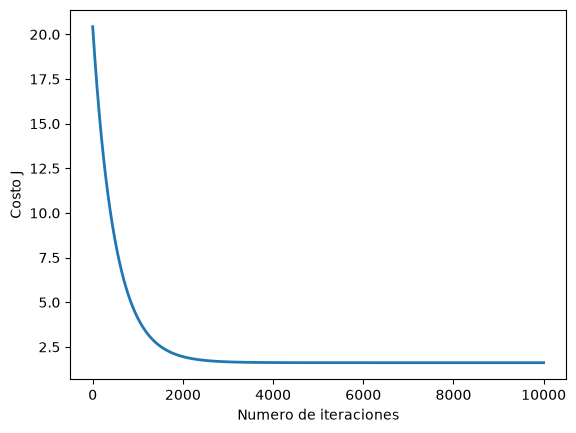

In [15]:
alpha = 0.001
num_iters = 10000

theta = np.zeros(X.shape[1])

theta, J_history = gradientDescentMulti(X, y, theta, alpha, num_iters)

pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta)))

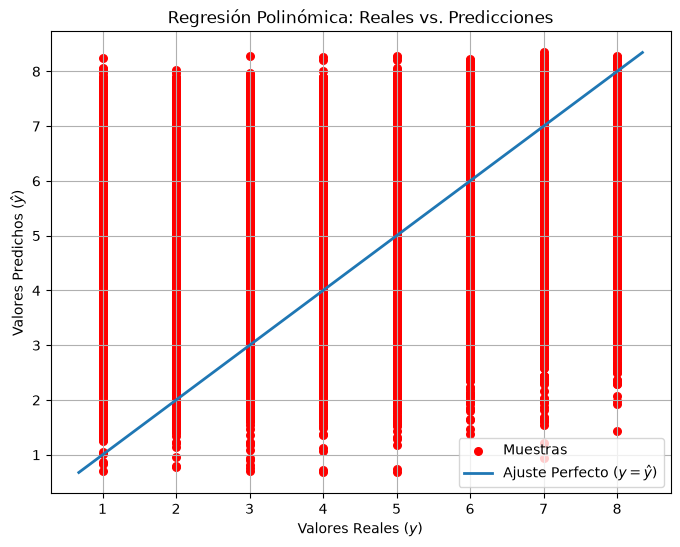

In [ ]:
y_pred = np.dot(X, theta)

y_real = y.flatten()
y_pred = y_pred.flatten()

pyplot.figure(figsize=(8, 6))
pyplot.scatter(y_real, y_pred, color='red', s=30, label='Muestras')

lim_min = min(y_real.min(), y_pred.min())
lim_max = max(y_real.max(), y_pred.max())
pyplot.plot([lim_min, lim_max], [lim_min, lim_max], '-', lw=2, label='Ajuste Perfecto ($y = \hat{y}$)')

pyplot.xlabel('Valores Reales ($y$)')
pyplot.ylabel('Valores Predichos ($\hat{y}$)')
pyplot.title('Regresión Polinómica: Reales vs. Predicciones')
pyplot.legend()
pyplot.grid(True)
pyplot.show()

## Solución Analítica: Ecuación Normal

La **Ecuación Normal** calcula directamente los parámetros óptimos ($\theta$) en un solo paso, sin algoritmos iterativos.

### 1. Fórmula

$$\theta = (X^T X)^{-1} X^T y$$

* **$X$:** Matriz de entradas con la columna de unos concatenada.
* **$y$:** Vector de variables objetivo.

---

### 2. Puntos Clave

* **Sin Ajustes:** No necesita tasa de aprendizaje ($\alpha$) ni número de iteraciones.
* **Sin Normalizar:** Funciona directamente sobre los datos sin escalar.
* **Gradiente Descendente vs. Ecuación Normal:** Usa Gradiente si tienes miles de características ($n > 10,000$), ya que calcular $(X^T X)^{-1}$ se vuelve muy lento ($\mathcal{O}(n^3)$). De lo contrario, la Ecuación Normal es más rápida y exacta.

In [ ]:
ruta_csv = os.path.join('datasets', 'diabetes.csv')
data_df = pd.read_csv(ruta_csv)

X = data_df.iloc[:, :20].values
y = data_df['Income'].values

m = y.size
print(f"Número de ejemplos de entrenamiento (m): {m}")

X = np.concatenate([np.ones((m, 1)), X], axis=1)

print("\nPrimeras 5 filas y primeras 4 columnas de X:")
print(X[:5, :4])

Número de ejemplos de entrenamiento (m): 253680

Primeras 5 filas y primeras 4 columnas de X:
[[1. 0. 1. 1.]
 [1. 0. 0. 0.]
 [1. 0. 1. 1.]
 [1. 0. 1. 0.]
 [1. 0. 1. 1.]]


In [ ]:
def normalEqn(X, y):

    theta = np.zeros(X.shape[1])

    theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T,X)),X.T),y)

    return theta


theta = normalEqn(X, y)

print('Theta calculado a partir de la ecuación de la normal: {:s}'.format(str(theta)))

Theta calculado a partir de la ecuación de la normal: [ 5.39997440e+00 -1.22010120e-01 -1.68888730e-01  1.14875198e-01
  2.29089535e-01  3.59689969e-03 -2.16867991e-01 -3.45296511e-01
 -1.49476048e-01  2.46886305e-01  8.81082541e-02  4.88097950e-01
  3.86382954e-01  1.24549015e+00 -7.57840276e-01 -3.63545667e-01
 -1.83101337e-02 -3.16459349e-03 -7.06989398e-01  5.10596864e-01
 -4.81682730e-02]
